# ExtraaLearn Project

## Context

The EdTech industry has been surging in the past decade immensely, and according to a forecast, the Online Education market would be worth $286.62bn by 2023 with a compound annual growth rate (CAGR) of 10.26% from 2018 to 2023. The modern era of online education has enforced a lot in its growth and expansion beyond any limit. Due to having many dominant features like ease of information sharing, personalized learning experience, transparency of assessment, etc, it is now preferable to traditional education.

In the present scenario due to the Covid-19, the online education sector has witnessed rapid growth and is attracting a lot of new customers. Due to this rapid growth, many new companies have emerged in this industry. With the availability and ease of use of digital marketing resources, companies can reach out to a wider audience with their offerings. The customers who show interest in these offerings are termed as leads. There are various sources of obtaining leads for Edtech companies, like

- The customer interacts with the marketing front on social media or other online platforms.
- The customer browses the website/app and downloads the brochure
- The customer connects through emails for more information.

The company then nurtures these leads and tries to convert them to paid customers. For this, the representative from the organization connects with the lead on call or through email to share further details.

## Objective

ExtraaLearn is an initial stage startup that offers programs on cutting-edge technologies to students and professionals to help them upskill/reskill. With a large number of leads being generated on a regular basis, one of the issues faced by ExtraaLearn is to identify which of the leads are more likely to convert so that they can allocate resources accordingly. You, as a data scientist at ExtraaLearn, have been provided the leads data to:

- Analyze and build an ML model to help identify which leads are more likely to convert to paid customers,
- Find the factors driving the lead conversion process
- Create a profile of the leads which are likely to convert

## Data Description

The data contains the different attributes of leads and their interaction details with ExtraaLearn. The detailed data dictionary is given below.

**Data Dictionary**

- ID: ID of the lead
- age: Age of the lead
- current_occupation: Current occupation of the lead. Values include 'Professional','Unemployed',and 'Student'
- first_interaction: How did the lead first interacted with ExtraaLearn. Values include 'Website', 'Mobile App'
- profile_completed: What percentage of profile has been filled by the lead on the website/mobile app. Values include Low - (0-50%), Medium - (50-75%), High (75-100%)
- website_visits: How many times has a lead visited the website
- time_spent_on_website: Total time spent on the website
- page_views_per_visit: Average number of pages on the website viewed during the visits.
- last_activity: Last interaction between the lead and ExtraaLearn.

  - Email Activity: Seeking for details about program through email, Representative shared information with lead like brochure of program , etc
  - Phone Activity: Had a Phone Conversation with representative, Had conversation over SMS with representative, etc
  - Website Activity: Interacted on live chat with representative, Updated profile on website, etc
- print_media_type1: Flag indicating whether the lead had seen the ad of ExtraaLearn in the Newspaper.
- print_media_type2: Flag indicating whether the lead had seen the ad of ExtraaLearn in the Magazine.
- digital_media: Flag indicating whether the lead had seen the ad of ExtraaLearn on the digital platforms.
- educational_channels: Flag indicating whether the lead had heard about ExtraaLearn in the education channels like online forums, discussion threads, educational websites, etc.
- referral: Flag indicating whether the lead had heard about ExtraaLearn through reference.
- status: Flag indicating whether the lead was converted to a paid customer or not.

## Importing necessary libraries and data

In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

import warnings
warnings.filterwarnings("ignore")

data = pd.read_csv("ExtraaLearn.csv")
learn = data.copy()
learn.head()

,ID,age,current_occupation,first_interaction,profile_completed,website_visits,time_spent_on_website,page_views_per_visit,last_activity,print_media_type1,print_media_type2,digital_media,educational_channels,referral,status
0,EXT001,57,Unemployed,Website,High,7,1639,1.861,Website Activity,Yes,No,Yes,No,No,1
1,EXT002,56,Professional,Mobile App,Medium,2,83,0.320,Website Activity,No,No,No,Yes,No,0
2,EXT003,52,Professional,Website,Medium,3,330,0.074,Website Activity,No,No,Yes,No,No,0
3,EXT004,53,Unemployed,Website,High,4,464,2.057,Website Activity,No,No,No,No,No,1
4,EXT005,23,Student,Website,High,4,600,16.914,Email Activity,No,No,No,No,No,0


## Data Overview

- Observations
- Sanity checks

In [4]:
print("Shape of the data:", learn.shape)
learn.info()

Shape of the data: (4612, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4612 entries, 0 to 4611
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID                     4612 non-null   object 
 1   age                    4612 non-null   int64  
 2   current_occupation     4612 non-null   object 
 3   first_interaction      4612 non-null   object 
 4   profile_completed      4612 non-null   object 
 5   website_visits         4612 non-null   int64  
 6   time_spent_on_website  4612 non-null   int64  
 7   page_views_per_visit   4612 non-null   float64
 8   last_activity          4612 non-null   object 
 9   print_media_type1      4612 non-null   object 
 10  print_media_type2      4612 non-null   object 
 11  digital_media          4612 non-null   object 
 12  educational_channels   4612 non-null   object 
 13  referral               4612 non-null   object 
 14  status                 461

In [5]:
learn.sample(5, random_state=1)

,ID,age,current_occupation,first_interaction,profile_completed,website_visits,time_spent_on_website,page_views_per_visit,last_activity,print_media_type1,print_media_type2,digital_media,educational_channels,referral,status
3823,EXT3824,18,Student,Mobile App,Medium,5,202,2.194,Website Activity,No,No,No,No,No,0
190,EXT191,19,Student,Mobile App,High,3,288,3.586,Phone Activity,No,No,Yes,No,No,0
2611,EXT2612,54,Unemployed,Website,Medium,5,1902,3.744,Website Activity,No,No,No,No,No,1
2404,EXT2405,63,Unemployed,Mobile App,Medium,2,85,8.597,Email Activity,No,No,No,Yes,No,0
4269,EXT4270,19,Student,Mobile App,High,3,81,2.124,Email Activity,No,No,No,Yes,No,0


In [6]:
print("Number of fully duplicated rows:", learn.duplicated().sum())
print("Number of duplicate lead IDs:", learn["ID"].duplicated().sum())

learn = learn.drop(columns=["ID"])

Number of fully duplicated rows: 0
Number of duplicate lead IDs: 0


In [7]:
learn.isnull().sum()

,0
age,0
current_occupation,0
first_interaction,0
profile_completed,0
website_visits,0
time_spent_on_website,0
page_views_per_visit,0
last_activity,0
print_media_type1,0
print_media_type2,0


In [8]:
learn.describe().T

,count,mean,std,min,25%,50%,75%,max
age,4612.0,46.201214,13.161454,18.0,36.00000,51.000,57.00000,63.000
website_visits,4612.0,3.566782,2.829134,0.0,2.00000,3.000,5.00000,30.000
time_spent_on_website,4612.0,724.011275,743.828683,0.0,148.75000,376.000,1336.75000,2537.000
page_views_per_visit,4612.0,3.026126,1.968125,0.0,2.07775,2.792,3.75625,18.434
status,4612.0,0.298569,0.457680,0.0,0.00000,0.000,1.00000,1.000


In [9]:
learn.describe(include=["object"]).T

,count,unique,top,freq
current_occupation,4612,3,Professional,2616
first_interaction,4612,2,Website,2542
profile_completed,4612,3,High,2264
last_activity,4612,3,Email Activity,2278
print_media_type1,4612,2,No,4115
print_media_type2,4612,2,No,4379
digital_media,4612,2,No,4085
educational_channels,4612,2,No,3907
referral,4612,2,No,4519


**Observations**

- 4,612 leads and 14 features after dropping `ID` (4 numeric, 9 categorical), plus the target `status`.
- No missing values and no duplicates.
- `age` ranges from 18 to 63.
- `website_visits` and `page_views_per_visit` have some high values that look like possible outliers.
- `time_spent_on_website` looks right-skewed (mean is a lot higher than the median).
- The target is imbalanced: about 70% did not convert, 30% did.

## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**

1. Leads will have different expectations from the outcome of the course and the current occupation may play a key role in getting them to participate in the program. Find out how current occupation affects lead status.
2. The company's first impression on the customer must have an impact. Do the first channels of interaction have an impact on the lead status?
3. The company uses multiple modes to interact with prospects. Which way of interaction works best?
4. The company gets leads from various channels such as print media, digital media, referrals, etc. Which of these channels have the highest lead conversion rate?
5. People browsing the website or mobile application are generally required to create a profile by sharing their personal data before they can access additional information.Does having more details about a prospect increase the chances of conversion?

### Univariate Analysis

In [10]:
def histogram_boxplot(data, feature, figsize=(12, 6), kde=False, bins=None):
    '''Plot a boxplot and a histogram along the same x-axis for a numerical feature.'''
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2, sharex=True, gridspec_kw={"height_ratios": (0.25, 0.75)}, figsize=figsize
    )
    sns.boxplot(data=data, x=feature, ax=ax_box2, showmeans=True, color="violet")
    sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, color="skyblue") if bins else \
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, color="skyblue")
    ax_hist2.axvline(data[feature].mean(), color="green", linestyle="--", label="Mean")
    ax_hist2.axvline(data[feature].median(), color="black", linestyle="-", label="Median")
    ax_hist2.legend()
    plt.show()


def labeled_barplot(data, feature, perc=False, n=None):
    '''Bar plot for a categorical feature with counts / percentages annotated.'''
    total = len(data[feature])
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 2, 5))
    else:
        plt.figure(figsize=(n + 2, 5))

    plt.xticks(rotation=0, fontsize=12)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].tolist(),
    )
    for p in ax.patches:
        if perc:
            label = "{:.1f}%".format(100 * p.get_height() / total)
        else:
            label = p.get_height()
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.annotate(label, (x, y), ha="center", va="center", size=12, xytext=(0, 5), textcoords="offset points")
    plt.show()

=============== age ===============


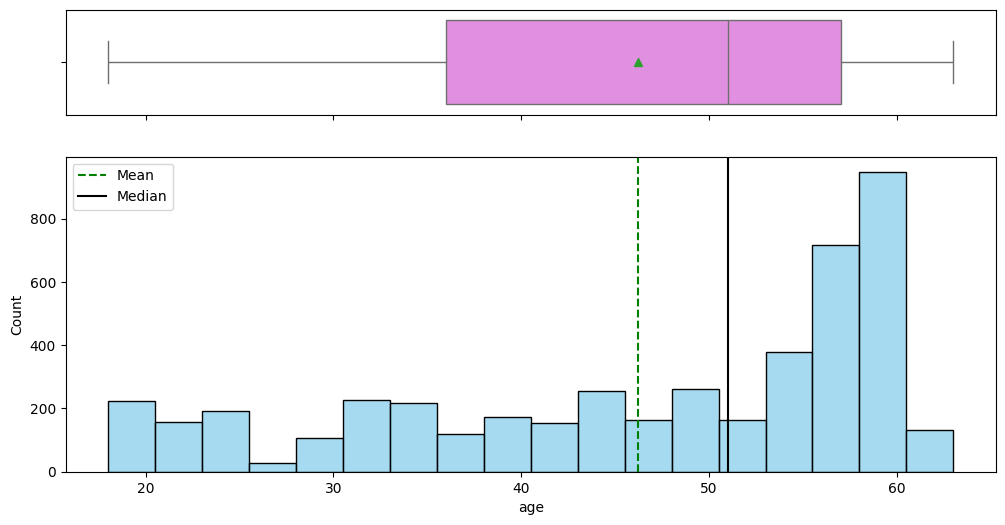

=============== website_visits ===============


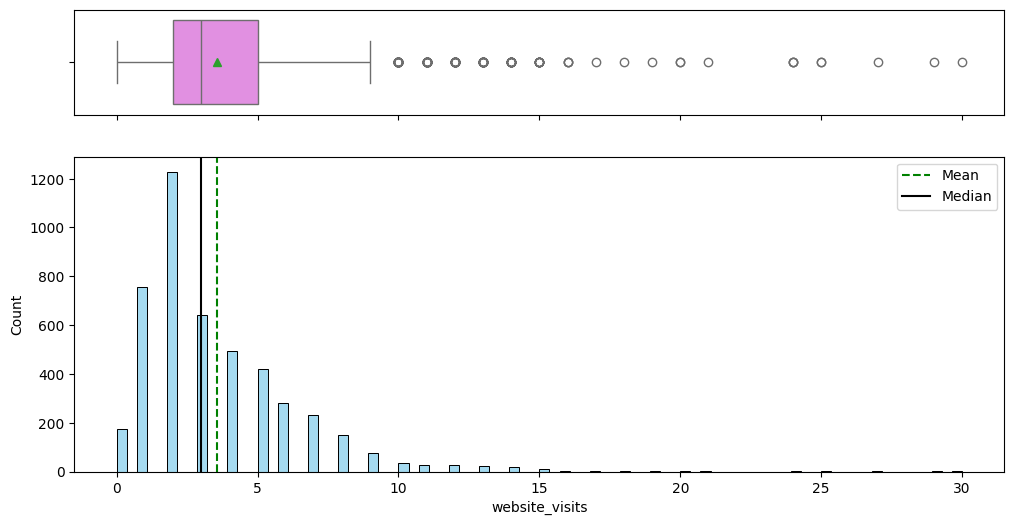

=============== time_spent_on_website ===============


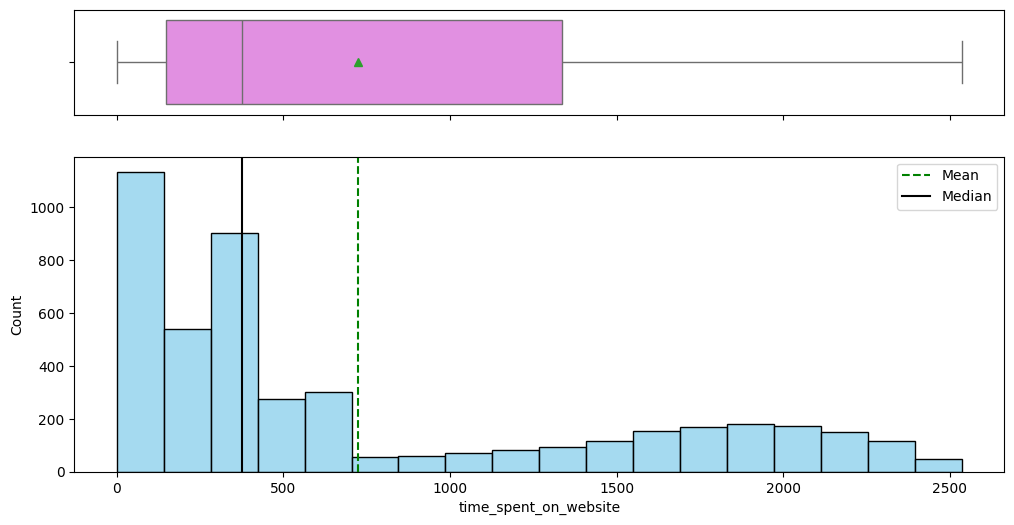

=============== page_views_per_visit ===============


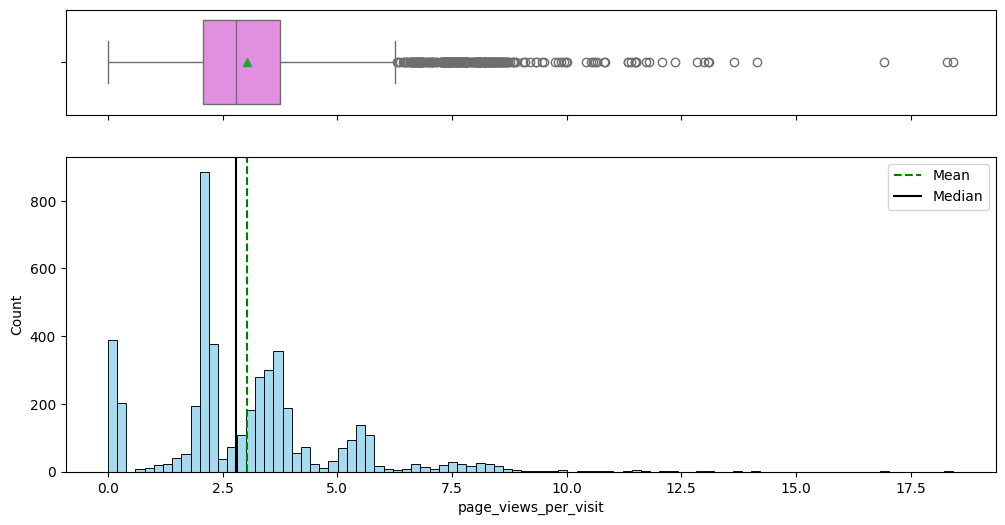

In [11]:
for col in ["age", "website_visits", "time_spent_on_website", "page_views_per_visit"]:
    print("=" * 15, col, "=" * 15)
    histogram_boxplot(learn, col)

=============== current_occupation ===============


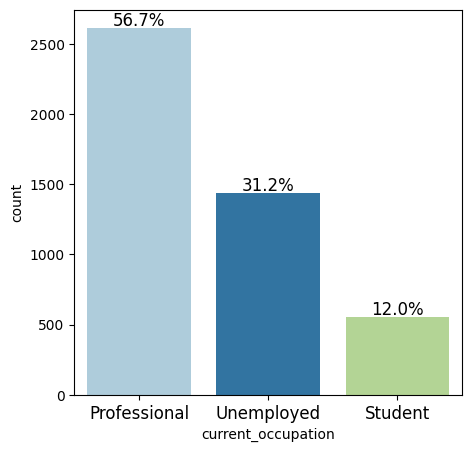

=============== first_interaction ===============


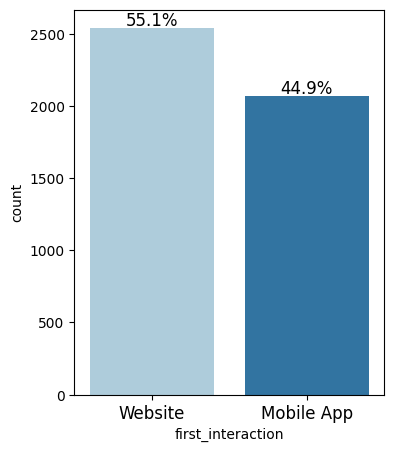

=============== profile_completed ===============


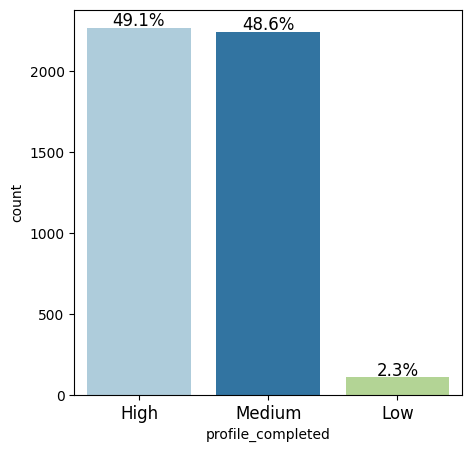

=============== last_activity ===============


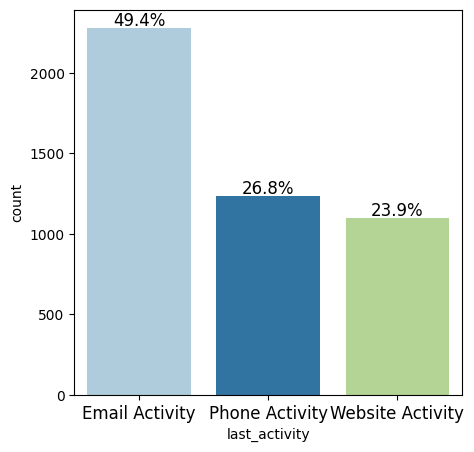

=============== print_media_type1 ===============


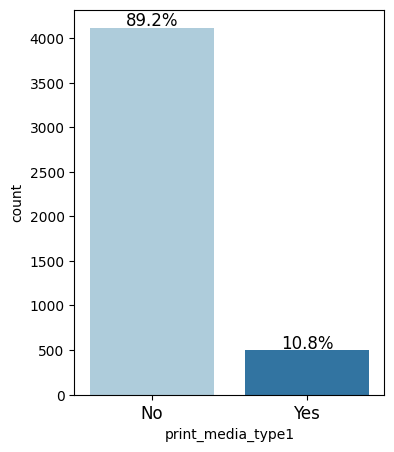

=============== print_media_type2 ===============


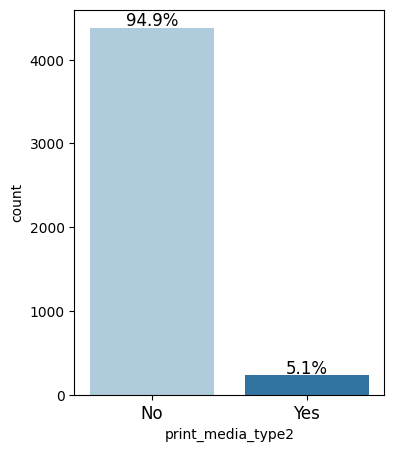

=============== digital_media ===============


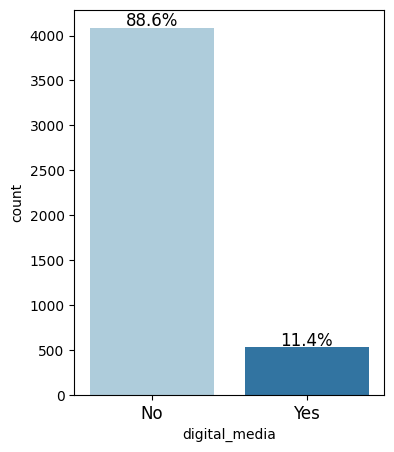

=============== educational_channels ===============


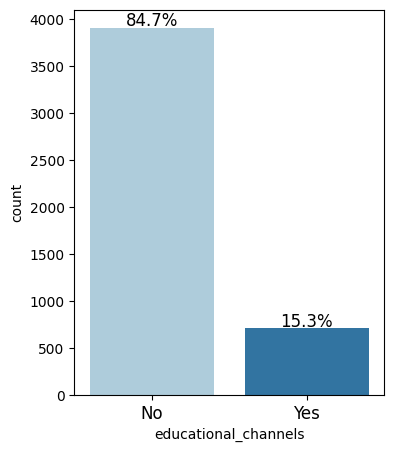

=============== referral ===============


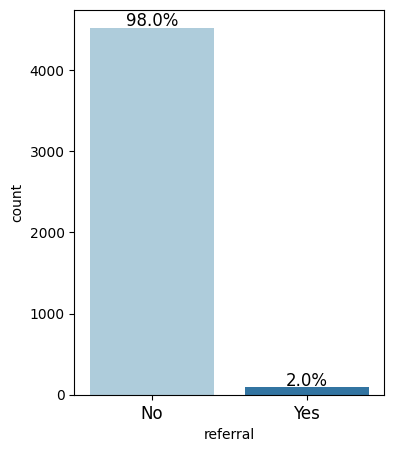

=============== status ===============


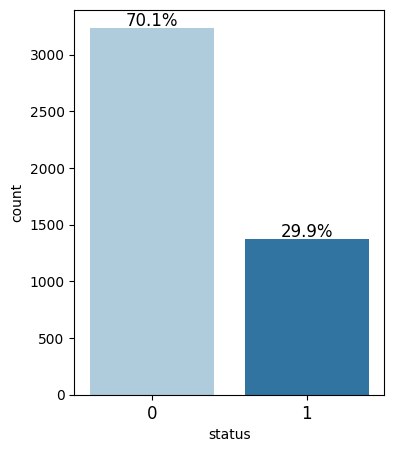

In [12]:
for col in ["current_occupation", "first_interaction", "profile_completed", "last_activity",
            "print_media_type1", "print_media_type2", "digital_media", "educational_channels",
            "referral", "status"]:
    print("=" * 15, col, "=" * 15)
    labeled_barplot(learn, col, perc=True)

**Observations**

- `age` is spread pretty evenly across 18–63, no big outliers.
- `website_visits` and `page_views_per_visit` are right-skewed with a few high outliers.
- `time_spent_on_website` is right-skewed — most leads spend little time, but some spend a lot more.
- Most leads are Professionals, then Unemployed, then Students.
- Slightly more leads first came in through the Website than the Mobile App.
- Most leads have a High or Medium completed profile; very few are Low.
- Email Activity is the most common last activity, then Phone, then Website.
- Most leads did **not** come from print media, digital media, educational channels, or referral — referral is the rarest source.
- About 30% of leads converted, matching what we saw earlier.

### Bivariate Analysis

In [13]:
def stacked_barplot(data, predictor, target):
    '''Stacked bar plot showing the % split of target within each level of a categorical predictor.'''
    tab = pd.crosstab(data[predictor], data[target], normalize="index") * 100
    print(tab.round(2))
    tab.plot(kind="bar", stacked=True, figsize=(8, 5))
    plt.legend(title="status", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.ylabel("Percentage")
    plt.title(f"{predictor} vs {target}")
    plt.show()

status                  0      1
current_occupation              
Professional        64.49  35.51
Student             88.29  11.71
Unemployed          73.42  26.58


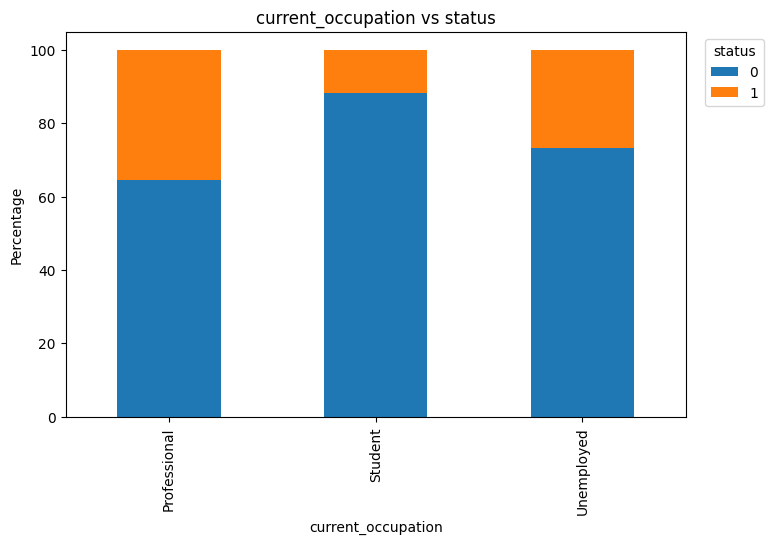

status                 0      1
first_interaction              
Mobile App         89.47  10.53
Website            54.41  45.59


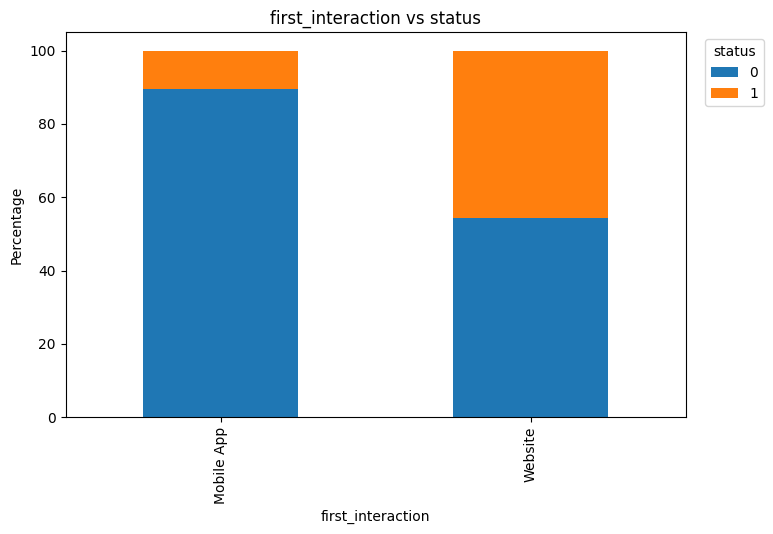

status                 0      1
profile_completed              
High               58.22  41.78
Low                92.52   7.48
Medium             81.12  18.88


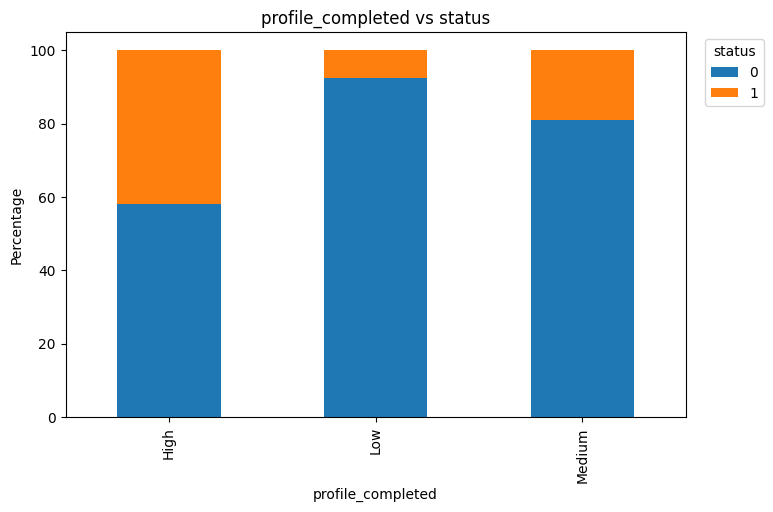

status                0      1
last_activity                 
Email Activity    69.67  30.33
Phone Activity    78.69  21.31
Website Activity  61.55  38.45


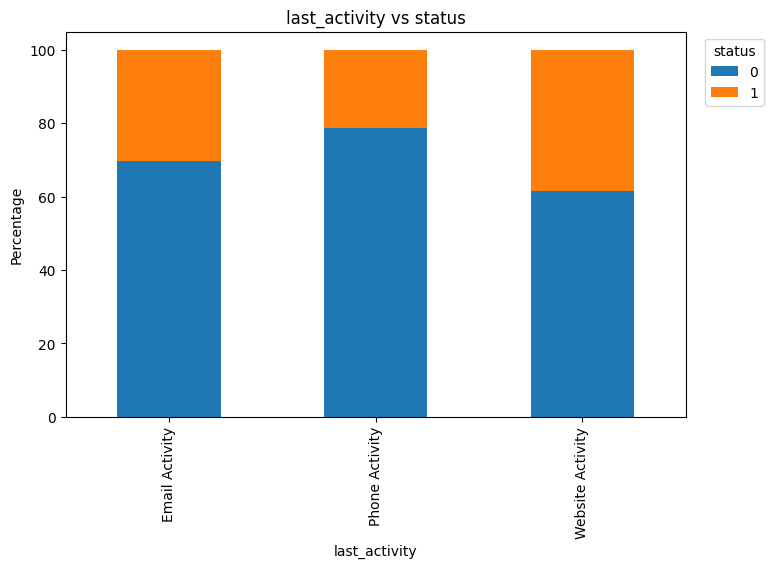

status                 0      1
print_media_type1              
No                 70.40  29.60
Yes                68.01  31.99


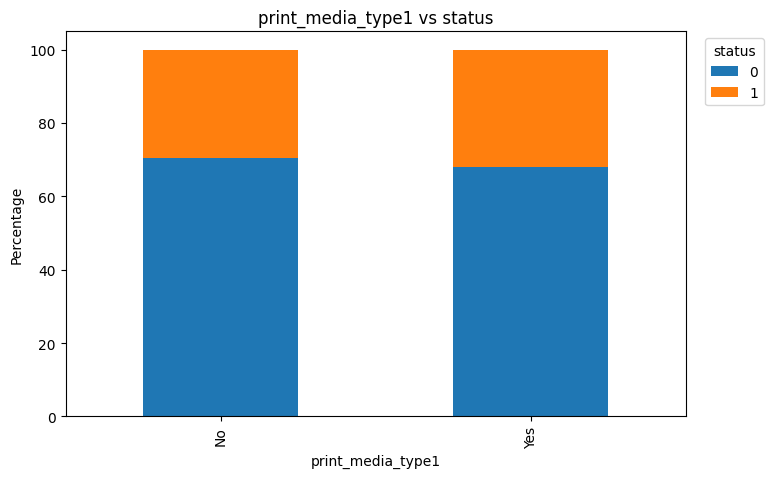

status                 0      1
print_media_type2              
No                 70.27  29.73
Yes                67.81  32.19


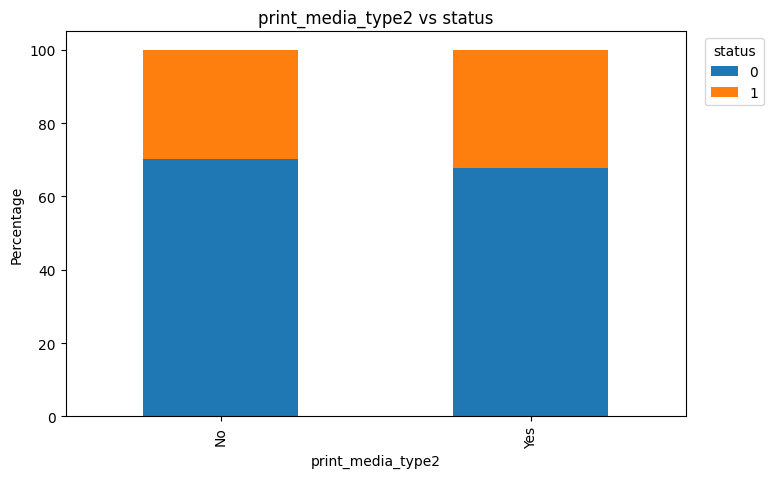

status             0      1
digital_media              
No             70.40  29.60
Yes            68.12  31.88


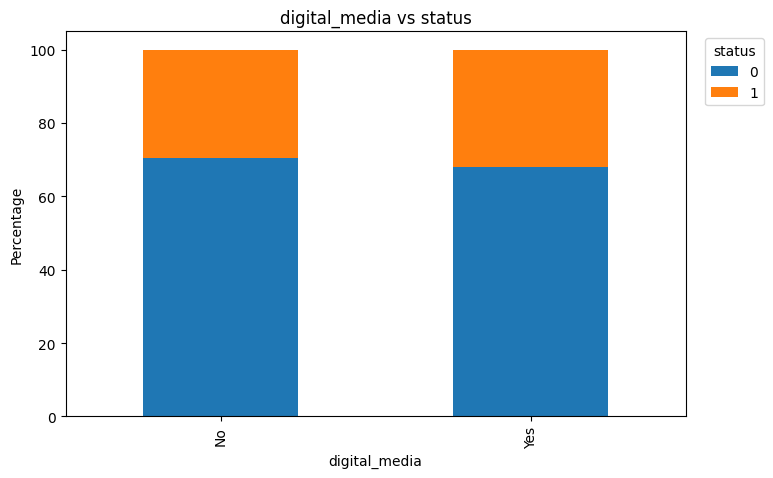

status                    0      1
educational_channels              
No                    69.80  30.20
Yes                   72.06  27.94


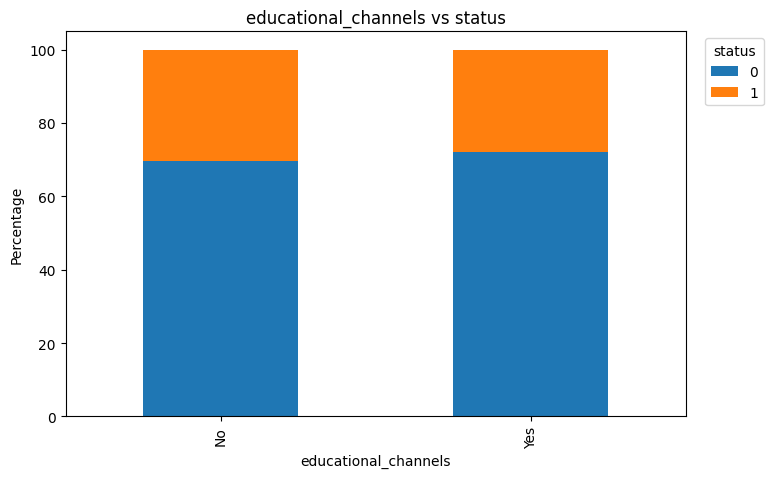

status        0      1
referral              
No        70.92  29.08
Yes       32.26  67.74


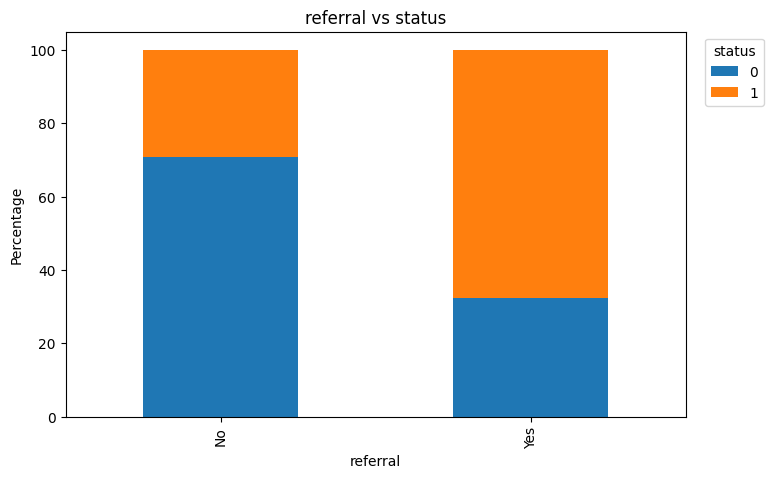

In [14]:
for col in ["current_occupation", "first_interaction", "profile_completed", "last_activity",
            "print_media_type1", "print_media_type2", "digital_media", "educational_channels", "referral"]:
    stacked_barplot(learn, col, "status")

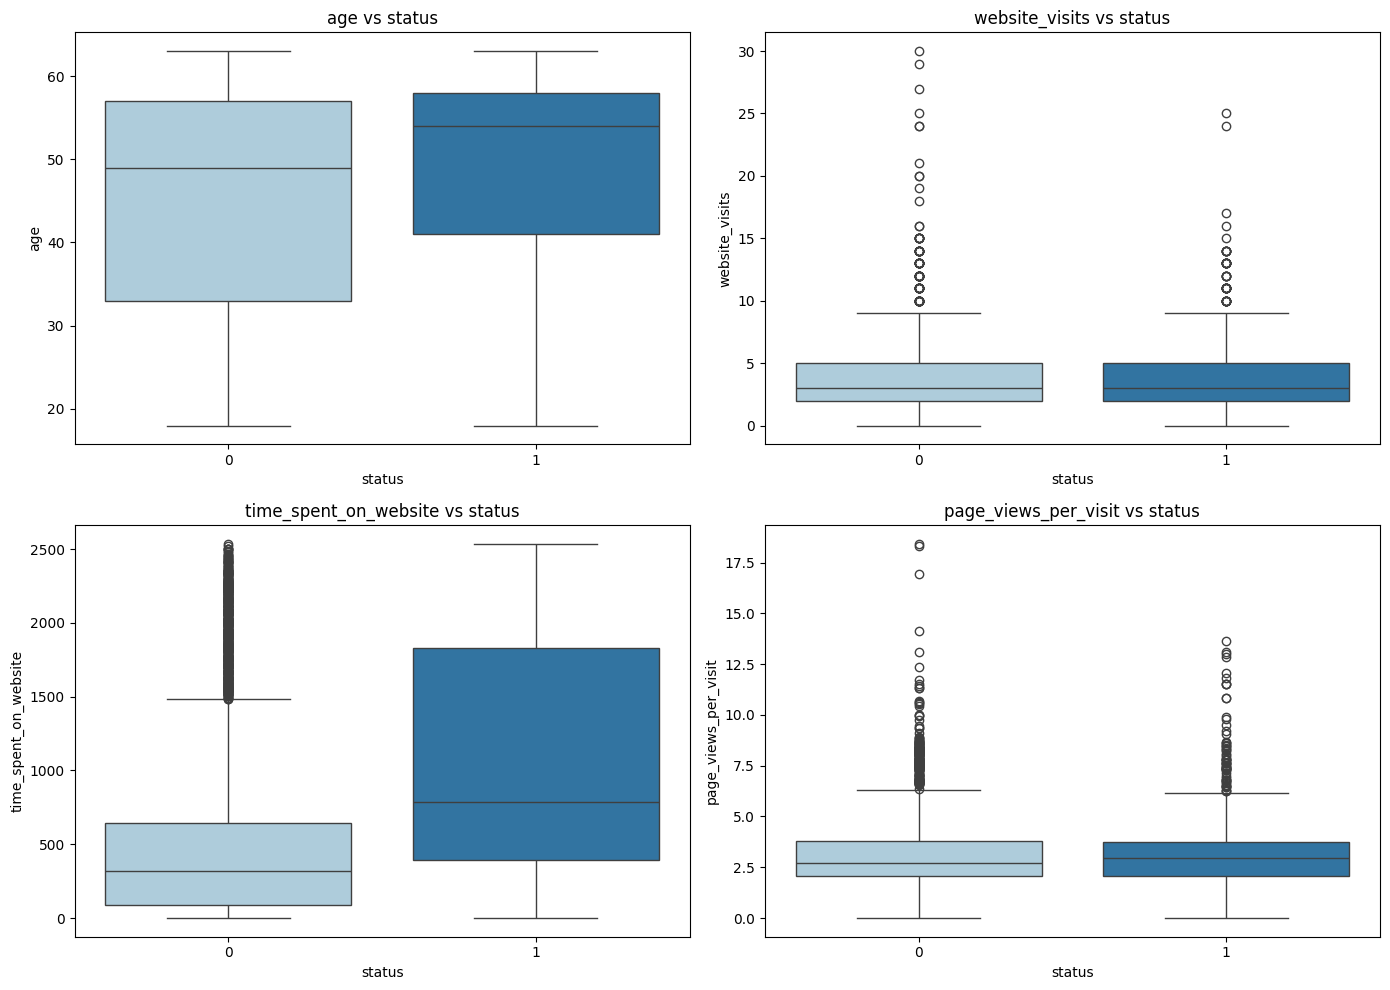

          age  website_visits  time_spent_on_website  page_views_per_visit
status                                                                    
0       45.15            3.58                 577.42                  3.03
1       48.66            3.54                1068.40                  3.03


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flatten(), ["age", "website_visits", "time_spent_on_website", "page_views_per_visit"]):
    sns.boxplot(data=learn, x="status", y=col, ax=ax, palette="Paired")
    ax.set_title(f"{col} vs status")
plt.tight_layout()
plt.show()

print(learn.groupby("status")[["age", "website_visits", "time_spent_on_website", "page_views_per_visit"]].mean().round(2))

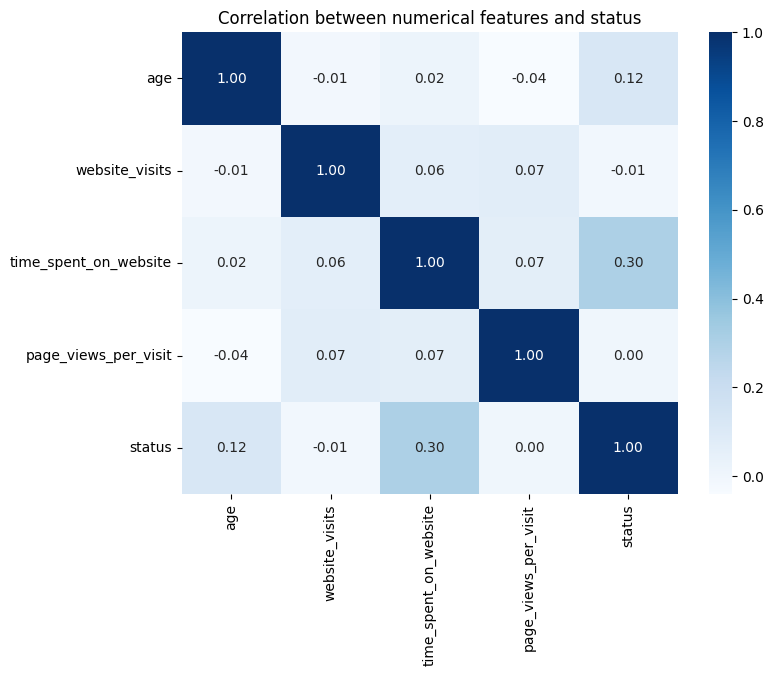

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    learn[["age", "website_visits", "time_spent_on_website", "page_views_per_visit", "status"]].corr(),
    annot=True, fmt=".2f", cmap="Blues"
)
plt.title("Correlation between numerical features and status")
plt.show()

**Observations & answers to the guiding questions**

1. **Occupation** — Professionals convert the most (~36%), then Unemployed (~27%), then Students (~12%).
2. **First interaction** — Big difference here: Website leads convert at ~46%, Mobile App leads only ~11%.
3. **Last activity** — Website Activity converts best (~39%), then Email (~30%), then Phone (~21%).
4. **Marketing channel** — Referral leads convert the most by far (~68%), but referral is a very small channel (~2% of leads). Print media, digital media, and educational channels don't seem to make much difference on their own.
5. **Profile completeness** — Higher completion means higher conversion: Low ~7%, Medium ~19%, High ~42%.
6. **Numeric features** — `time_spent_on_website` is clearly higher for converted leads (~1,068 vs ~577 seconds on average). `age` has a small positive effect. `website_visits` and `page_views_per_visit` don't really relate to conversion — visiting a lot doesn't mean much on its own.

## Data Preprocessing

- Missing value treatment (if needed)
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

In [17]:
num_cols = ["age", "website_visits", "time_spent_on_website", "page_views_per_visit"]
for col in num_cols:
    q1 = learn[col].quantile(0.25)
    q3 = learn[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    pct_outliers = ((learn[col] < lower) | (learn[col] > upper)).mean() * 100
    print(f"{col}: {pct_outliers:.2f}% flagged as outliers (IQR rule)")

age: 0.00% flagged as outliers (IQR rule)
website_visits: 3.34% flagged as outliers (IQR rule)
time_spent_on_website: 0.00% flagged as outliers (IQR rule)
page_views_per_visit: 5.57% flagged as outliers (IQR rule)


In [18]:
X = learn.drop(columns=["status"])
Y = learn["status"]

X = pd.get_dummies(X, drop_first=True)
X.head()

,age,website_visits,time_spent_on_website,page_views_per_visit,current_occupation_Student,current_occupation_Unemployed,first_interaction_Website,profile_completed_Low,profile_completed_Medium,last_activity_Phone Activity,last_activity_Website Activity,print_media_type1_Yes,print_media_type2_Yes,digital_media_Yes,educational_channels_Yes,referral_Yes
0,57,7,1639,1.861,False,True,True,False,False,False,True,True,False,True,False,False
1,56,2,83,0.320,False,False,False,False,True,False,True,False,False,False,True,False
2,52,3,330,0.074,False,False,True,False,True,False,True,False,False,True,False,False
3,53,4,464,2.057,False,True,True,False,False,False,True,False,False,False,False,False
4,23,4,600,16.914,True,False,True,False,False,False,False,False,False,False,False,False


In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=1, stratify=Y)

print("Shape of training set:", X_train.shape)
print("Shape of test set:", X_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Shape of training set: (3228, 16)
Shape of test set: (1384, 16)
Percentage of classes in training set:
status
0    0.701363
1    0.298637
Name: proportion, dtype: float64
Percentage of classes in test set:
status
0    0.70159
1    0.29841
Name: proportion, dtype: float64


**Observations**

- No missing values, so no imputation needed.
- No new features were created — the existing columns already look predictive enough.
- Some outliers show up in `website_visits` and `page_views_per_visit`, but we kept them since they look like real high-engagement leads and tree models aren't very sensitive to outliers anyway.
- `ID` was already dropped since it's just an identifier.
- Categorical columns were one-hot encoded.
- Split into 70% train / 30% test, stratified on `status` so both sets keep the same class balance.

## EDA

- It is a good idea to explore the data once again after manipulating it.

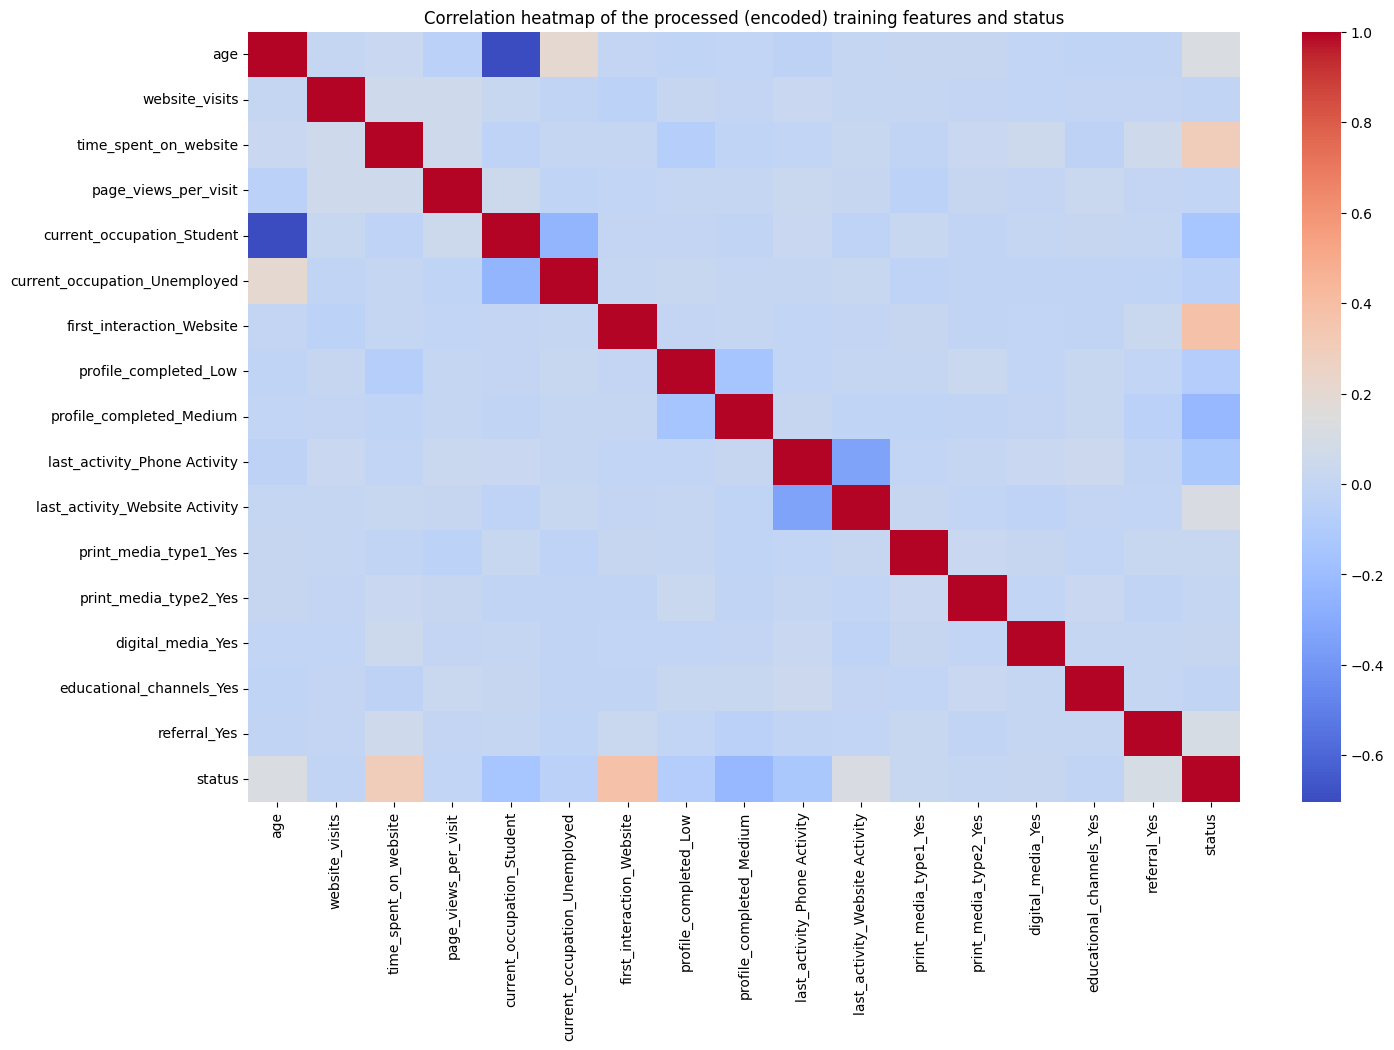

In [20]:
plt.figure(figsize=(16, 10))
sns.heatmap(pd.concat([X_train, y_train], axis=1).corr(), cmap="coolwarm", annot=False)
plt.title("Correlation heatmap of the processed (encoded) training features and status")
plt.show()

**Observations**

- `first_interaction_Website`, `profile_completed_Medium`, and `time_spent_on_website` still look like the strongest predictors, matching the bivariate analysis.
- No pair of predictors is highly correlated with each other, so nothing needs to be dropped before modeling.

## Building a Decision Tree model

In [21]:
def model_performance_classification(model, predictors, target):
    '''Return a one-row dataframe of Accuracy / Recall / Precision / F1 for a fitted classifier.'''
    pred = model.predict(predictors)
    return pd.DataFrame(
        {
            "Accuracy": [accuracy_score(target, pred)],
            "Recall": [recall_score(target, pred)],
            "Precision": [precision_score(target, pred)],
            "F1": [f1_score(target, pred)],
        }
    )


def confusion_matrix_plot(model, predictors, target):
    '''Plot an annotated confusion matrix (counts + row-wise %) for a fitted classifier.'''
    pred = model.predict(predictors)
    cm = confusion_matrix(target, pred)
    labels = np.asarray(
        [f"{v:0.0f}\n{p:.1%}" for v, p in zip(cm.flatten(), (cm / cm.sum(axis=1, keepdims=True)).flatten())]
    ).reshape(2, 2)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", xticklabels=["Not converted", "Converted"],
                yticklabels=["Not converted", "Converted"])
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.show()

Training performance:
   Accuracy    Recall  Precision        F1
0   0.99938  0.997925        1.0  0.998962

Test performance:
   Accuracy    Recall  Precision        F1
0  0.808526  0.668281   0.683168  0.675643


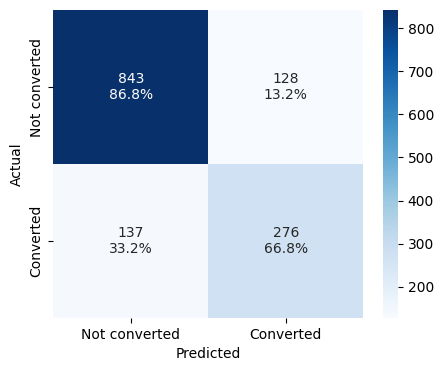

In [22]:
d_tree = DecisionTreeClassifier(random_state=1)
d_tree.fit(X_train, y_train)

print("Training performance:")
dt_train_perf = model_performance_classification(d_tree, X_train, y_train)
print(dt_train_perf)

print("\nTest performance:")
dt_test_perf = model_performance_classification(d_tree, X_test, y_test)
print(dt_test_perf)

confusion_matrix_plot(d_tree, X_test, y_test)

**Observations**

- The default tree scores almost perfectly on training data (recall ≈ 1.00) but drops a lot on test data (recall ≈ 0.67) — this is overfitting.
- Recall matters most here since we don't want to miss leads who would actually convert, so this model needs tuning.

## Do we need to prune the tree?

Best parameters: {'criterion': 'gini', 'max_depth': np.int64(4), 'min_samples_leaf': 5}

Training performance:
   Accuracy    Recall  Precision        F1
0  0.831475  0.893154    0.66129  0.759929

Test performance:
   Accuracy    Recall  Precision        F1
0  0.819364  0.869249   0.646847  0.741736


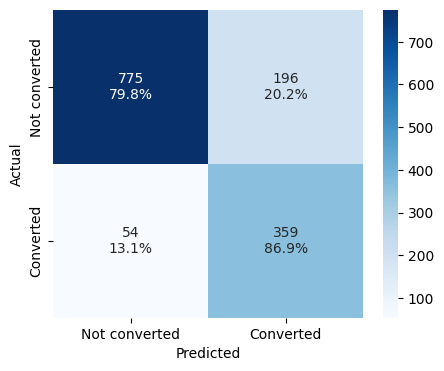

In [23]:
dt_estimator = DecisionTreeClassifier(random_state=1, class_weight="balanced")

param_grid_dt = {
    "max_depth": np.arange(2, 15, 2),
    "min_samples_leaf": [5, 10, 20, 30],
    "criterion": ["gini", "entropy"],
}

grid_dt = GridSearchCV(estimator=dt_estimator, param_grid=param_grid_dt, scoring="recall", cv=5, n_jobs=-1)
grid_dt.fit(X_train, y_train)

d_tree_tuned = grid_dt.best_estimator_
print("Best parameters:", grid_dt.best_params_)

print("\nTraining performance:")
dt_tuned_train_perf = model_performance_classification(d_tree_tuned, X_train, y_train)
print(dt_tuned_train_perf)

print("\nTest performance:")
dt_tuned_test_perf = model_performance_classification(d_tree_tuned, X_test, y_test)
print(dt_tuned_test_perf)

confusion_matrix_plot(d_tree_tuned, X_test, y_test)

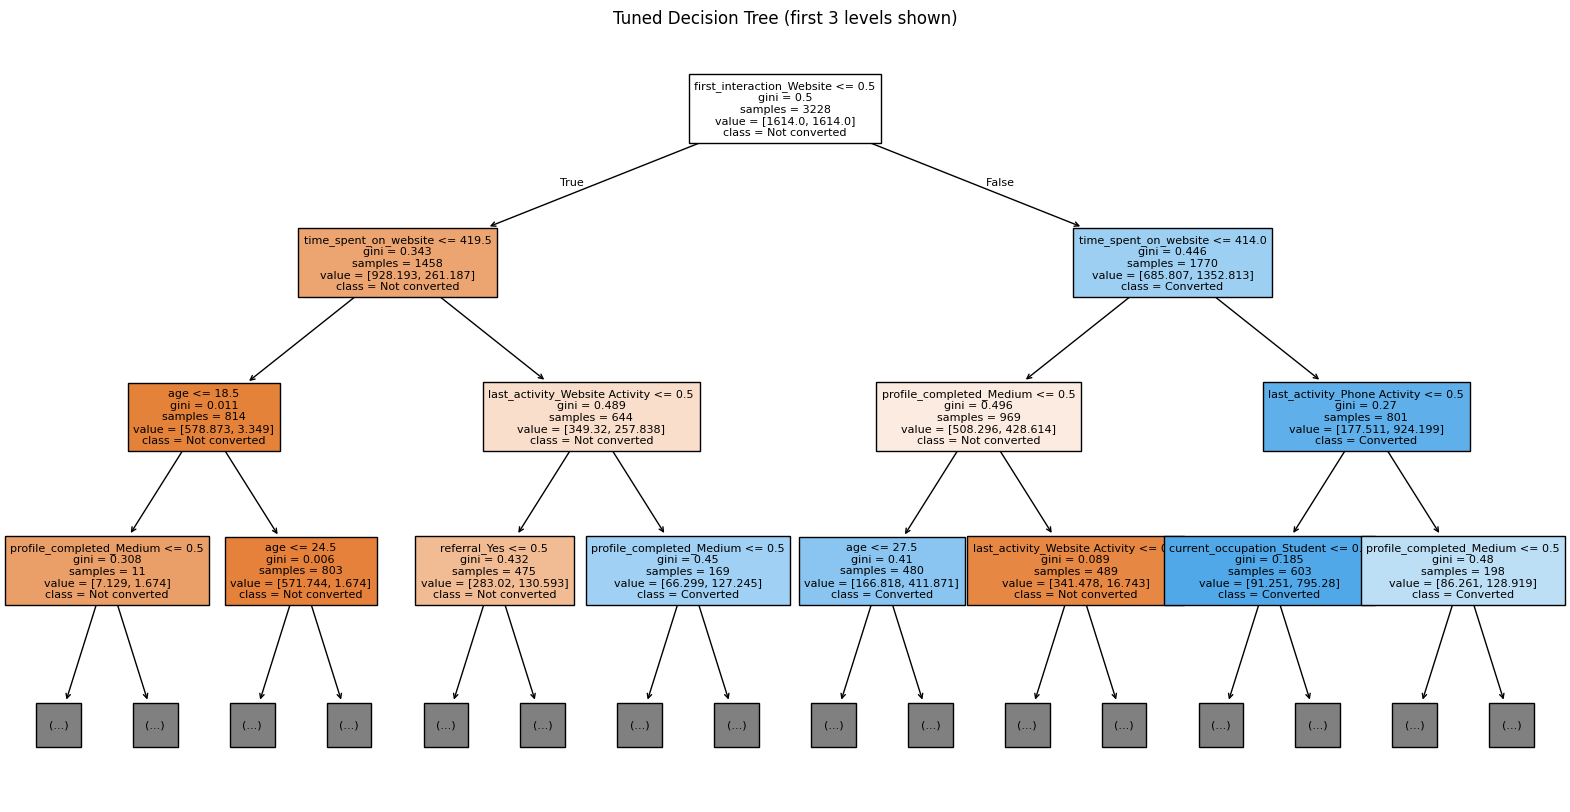

In [24]:
plt.figure(figsize=(20, 10))
plot_tree(d_tree_tuned, feature_names=list(X.columns), filled=True, fontsize=8, max_depth=3, class_names=["Not converted", "Converted"])
plt.title("Tuned Decision Tree (first 3 levels shown)")
plt.show()

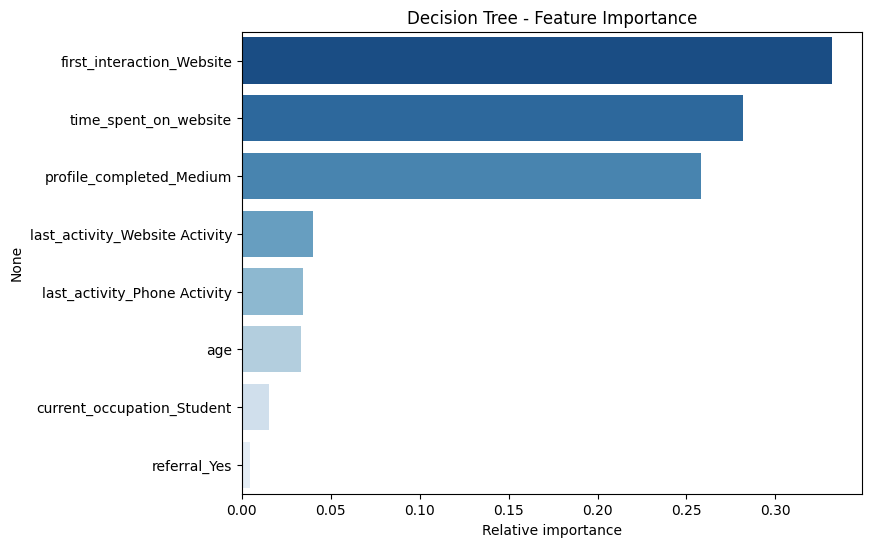

,0
first_interaction_Website,0.331979
time_spent_on_website,0.282067
profile_completed_Medium,0.258184
last_activity_Website Activity,0.040265
last_activity_Phone Activity,0.034462
age,0.033176
current_occupation_Student,0.015080
referral_Yes,0.004786


In [25]:
dt_importances = pd.Series(d_tree_tuned.feature_importances_, index=X.columns).sort_values(ascending=False)
dt_importances = dt_importances[dt_importances > 0]

plt.figure(figsize=(8, 6))
sns.barplot(x=dt_importances.values, y=dt_importances.index, palette="Blues_r")
plt.title("Decision Tree - Feature Importance")
plt.xlabel("Relative importance")
plt.show()
dt_importances

**Observations**

- After tuning with `GridSearchCV`, test recall jumps to about 0.87 and the train/test gap is much smaller — less overfitting.
- The top features are `first_interaction_Website`, `time_spent_on_website`, and `profile_completed_Medium`, which matches what the EDA already showed.

## Building a Random Forest model

Training performance:
   Accuracy  Recall  Precision        F1
0   0.99938     1.0    0.99793  0.998964

Test performance:
   Accuracy    Recall  Precision        F1
0  0.858382  0.733656    0.77892  0.755611


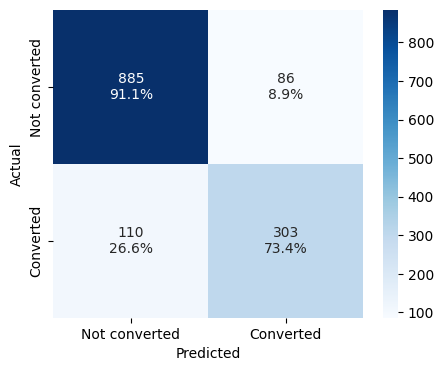

In [26]:
rf_estimator = RandomForestClassifier(random_state=1)
rf_estimator.fit(X_train, y_train)

print("Training performance:")
rf_train_perf = model_performance_classification(rf_estimator, X_train, y_train)
print(rf_train_perf)

print("\nTest performance:")
rf_test_perf = model_performance_classification(rf_estimator, X_test, y_test)
print(rf_test_perf)

confusion_matrix_plot(rf_estimator, X_test, y_test)

**Observations**

- Same pattern as the Decision Tree: near-perfect on training data, worse on test data. Still overfitting.
- Test recall isn't high enough yet, so we tune it next.

## Do we need to prune the tree?

Best parameters: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 100}

Training performance:
   Accuracy    Recall  Precision        F1
0  0.839529  0.884855   0.676984  0.767086

Test performance:
   Accuracy    Recall  Precision        F1
0  0.827312  0.859564   0.662313  0.748156


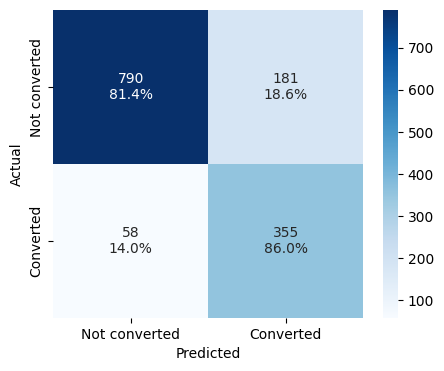

In [27]:
rf_tuned_estimator = RandomForestClassifier(random_state=1, class_weight="balanced")

param_grid_rf = {
    "n_estimators": [100, 150],
    "max_depth": [5, 7, 9],
    "min_samples_leaf": [5, 10, 20],
    "max_features": ["sqrt", "log2"],
}

grid_rf = GridSearchCV(estimator=rf_tuned_estimator, param_grid=param_grid_rf, scoring="recall", cv=5, n_jobs=-1)
grid_rf.fit(X_train, y_train)

rf_tuned = grid_rf.best_estimator_
print("Best parameters:", grid_rf.best_params_)

print("\nTraining performance:")
rf_tuned_train_perf = model_performance_classification(rf_tuned, X_train, y_train)
print(rf_tuned_train_perf)

print("\nTest performance:")
rf_tuned_test_perf = model_performance_classification(rf_tuned, X_test, y_test)
print(rf_tuned_test_perf)

confusion_matrix_plot(rf_tuned, X_test, y_test)

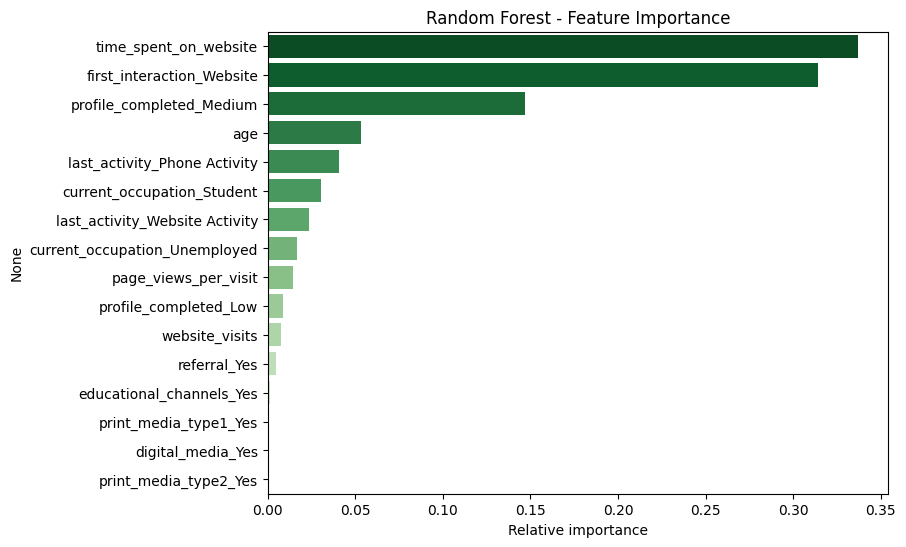

,0
time_spent_on_website,0.337142
first_interaction_Website,0.314146
profile_completed_Medium,0.146883
age,0.053239
last_activity_Phone Activity,0.040906
current_occupation_Student,0.030355
last_activity_Website Activity,0.023679
current_occupation_Unemployed,0.016544
page_views_per_visit,0.014159
profile_completed_Low,0.008416


In [30]:
rf_importances = pd.Series(rf_tuned.feature_importances_, index=X.columns).sort_values(ascending=False)
rf_importances = rf_importances[rf_importances > 0]

plt.figure(figsize=(8, 6))
sns.barplot(x=rf_importances.values, y=rf_importances.index, palette="Greens_r")
plt.title("Random Forest - Feature Importance")
plt.xlabel("Relative importance")
plt.show()
rf_importances

**Observations**

- Tuning brings test recall up to about 0.86, close to the tuned Decision Tree, with slightly better precision.
- Feature importance mostly agrees with the Decision Tree: `time_spent_on_website`, `first_interaction_Website`, and `profile_completed_Medium` are the top drivers.
- `referral` had the highest conversion rate in the EDA but ranks low here, probably because there just aren't many referral leads for the model to learn from.

### Comparing the models

In [28]:
comparison = pd.concat(
    [
        dt_train_perf.assign(Model="Decision Tree (default)", Set="Train"),
        dt_test_perf.assign(Model="Decision Tree (default)", Set="Test"),
        dt_tuned_train_perf.assign(Model="Decision Tree (tuned)", Set="Train"),
        dt_tuned_test_perf.assign(Model="Decision Tree (tuned)", Set="Test"),
        rf_train_perf.assign(Model="Random Forest (default)", Set="Train"),
        rf_test_perf.assign(Model="Random Forest (default)", Set="Test"),
        rf_tuned_train_perf.assign(Model="Random Forest (tuned)", Set="Train"),
        rf_tuned_test_perf.assign(Model="Random Forest (tuned)", Set="Test"),
    ],
    ignore_index=True,
)[["Model", "Set", "Accuracy", "Recall", "Precision", "F1"]]

comparison.round(3)

,Model,Set,Accuracy,Recall,Precision,F1
0,Decision Tree (default),Train,0.999,0.998,1.000,0.999
1,Decision Tree (default),Test,0.809,0.668,0.683,0.676
2,Decision Tree (tuned),Train,0.831,0.893,0.661,0.760
3,Decision Tree (tuned),Test,0.819,0.869,0.647,0.742
4,Random Forest (default),Train,0.999,1.000,0.998,0.999
5,Random Forest (default),Test,0.858,0.734,0.779,0.756
6,Random Forest (tuned),Train,0.840,0.885,0.677,0.767
7,Random Forest (tuned),Test,0.827,0.860,0.662,0.748


**Observations**

- Both default models overfit; tuning fixes most of that and raises test recall for both.
- The tuned Decision Tree has slightly higher recall (~0.87 vs ~0.86), but the tuned Random Forest has better precision and accuracy.
- We'll go with the tuned **Random Forest** as the main model since it's an ensemble and tends to be more stable, but the tuned Decision Tree is a reasonable alternative.

## Actionable Insights and Recommendations

In [31]:
top_features = pd.concat([dt_importances.rename("Decision Tree"), rf_importances.rename("Random Forest")], axis=1
).fillna(0).sort_values("Random Forest", ascending=False)

top_features.round(3)

,Decision Tree,Random Forest
time_spent_on_website,0.282,0.337
first_interaction_Website,0.332,0.314
profile_completed_Medium,0.258,0.147
age,0.033,0.053
last_activity_Phone Activity,0.034,0.041
current_occupation_Student,0.015,0.030
last_activity_Website Activity,0.040,0.024
current_occupation_Unemployed,0.000,0.017
page_views_per_visit,0.000,0.014
profile_completed_Low,0.000,0.008


### Key findings

- The first interaction channel matters most: Website leads convert about 4x more often than Mobile App leads
- Time spent on the site matters more than how often someone visits — converted leads spend about twice as long on average, but visit count and pages per visit don't really predict conversion.
- More profile completion means more conversion
- Professionals convert more than Unemployed or Student leads.
- Referral leads convert the best by far, but there are very few of them.
- Print media, digital media, and educational channels don't seem to move the needle much.

### Profile of a lead likely to convert

A Professional who first came in through the Website, has a High or Medium completed profile, spends more time on the site than average, and was last active on the website itself. Referral leads are also very likely to convert, even though there aren't many of them.

### Recommendations

1. Use the model's predictions to prioritize which leads to reach out to first.
2. Improve the Mobile App experience or push more leads toward the Website, since that's the strongest driver of conversion.
3. Find ways to get leads to spend more time engaging with the site, not just visit more often.
4. Encourage leads to complete more of their profile
5. Grow the referral program as it's small right now but converts very well.
6. Reconsider spend on print media and educational channels since they don't show much impact here.